# Augment rare cell types

A reference with few cells of some types trains a model that under-calls them.
`augment_data()` balances the classes: types below `norm_number` cells get simulated
cells, and with `prune=True` larger types are down-sampled. The simulated cells draw
molecules from the pooled counts of their type. This tutorial follows the R article
[How to augment data using viewmastR](https://furlan-lab.github.io/viewmastR/articles/Augment.html).

| Role | Dataset |
|---|---|
| Reference | BoneMarrowMap healthy bone marrow atlas (Zeng et al. 2025), 263,159 cells, finest labels `CellType` (55 types) |
| Query | T-cell-depleted bone marrow, multiome RNA, 8,627 cells with the authors' labels and UMAP (Persad et al. 2023; the file the [Mellon](https://github.com/settylab/Mellon) tutorial uses) |

The steps below are the ones `tutorial_data.bonemarrowmap_augmented()` runs for tutorial 01 and the README figure,
with the same seeds, so both tutorials use the same reference.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from sklearn.neighbors import NearestNeighbors
import viewmastr as vm
import readme_panels as rp
import tutorial_data as td

sc.set_figure_params(dpi=80, frameon=False)
plt.rcParams.update(rp.STYLE)
col = "CellType"
ref = td.bonemarrowmap_reference()  # 3.7 GB download on first use; about 12 GB in memory
print(ref.obs[col].value_counts().to_string())

CellType
CD4 Naive                      24063
CD14 Mono                      23957
HSC                            12641
CD4 Central Memory             12152
Early GMP                      11432
Cycling Progenitor              9366
CD8 Naive                       8502
CD8 Effector Memory 2           8486
Pro-Erythroblast                7390
CD4 Effector Memory             7361
CFU-E                           7318
Mature B                        6730
LMPP                            6718
BFU-E                           6554
MPP-MkEry                       5771
NK                              5771
MPP-MyLy                        5591
Basophilic Erythroblast         5253
Early ProMono                   5086
Polychromatic Erythroblast      5061
CD16 Mono                       4996
Pro-B VDJ                       4909
MEP                             4856
GMP-Mono                        4557
pDC                             4269
Orthochromatic Erythroblast     3734
cDC2                         

## Hold out real cells for an honest test

Keep 20 % of the real cells of every type aside (at most 1,000 per type). Both models
below train on the other cells; only the second one is augmented. The held-out cells are
never simulated.

In [2]:
train, held = td.bonemarrowmap_split(ref, col, holdout=0.2, max_held=1000, seed=0)
del ref
print(train.shape, held.shape)

(227584, 34009) (35575, 34009)


## Augment to 3,000 cells per type

Types below 3,000 cells get simulated cells; with `prune=True` larger types are randomly
down-sampled to 3,000. The real cells that remain are the "not augmented" reference below,
so the two models differ only by the simulated cells.

In [3]:
aug = vm.augment_data(train, col, norm_number=3000, prune=True, seed=0)
aug.obs["simulated"] = aug.obs_names.str.startswith("stimcell_")
real = aug[~aug.obs["simulated"].to_numpy()].copy()
n = pd.DataFrame({"real cells": train.obs[col].value_counts(),
                  "kept": real.obs[col].value_counts(),
                  "simulated": aug.obs.loc[aug.obs["simulated"], col].value_counts(),
                  "after": aug.obs[col].value_counts()}).fillna(0).astype(int)
print(n.sort_values("real cells").to_string())
rare = n.index[n["simulated"] > 0]
atlas_umap = pd.DataFrame(train.obsm["X_umap"], index=train.obs_names)  # the atlas's stored UMAP
del train

                             real cells  kept  simulated  after
CellType                                                       
Megakaryocyte                        44    44       2956   3000
Stromal                             171   171       2829   3000
NK Proliferating                    172   172       2828   3000
cDC1                                296   296       2704   3000
MLP-II                              405   405       2595   3000
ASDC                                442   442       2558   3000
T Proliferating                     464   464       2536   3000
Pre-ProB                            630   630       2370   3000
Pro-B Cycling                       895   895       2105   3000
Small Pre-B                         971   971       2029   3000
MLP                                 994   994       2006   3000
CLP                                1020  1020       1980   3000
CD8 Tissue Resident Memory         1183  1183       1817   3000
CD4 Regulatory                     1231 

The simulated cells should sit with the real cells of their type. The atlas joins six
studies, and its stored UMAP corrects for the study (Harmony). A new UMAP of the raw counts
does not. It splits the real cells by study, and the simulated cells, which belong to no study,
form islands of their own. So this check does not make a new UMAP. It keeps the real cells at
their atlas positions. It places each simulated cell at the median position of its 15 nearest
real cells, found in a PCA of the real cells. The check uses 300 cells per type.

simulated cells whose nearest real cells are mostly their own type: 0.776
Megakaryocyte       0.000
MLP                 0.332
CD4 Regulatory      0.393
Pre-ProB            0.557
NK Proliferating    0.564
NK CD56high         0.576
MLP-II              0.592
CLP                 0.754


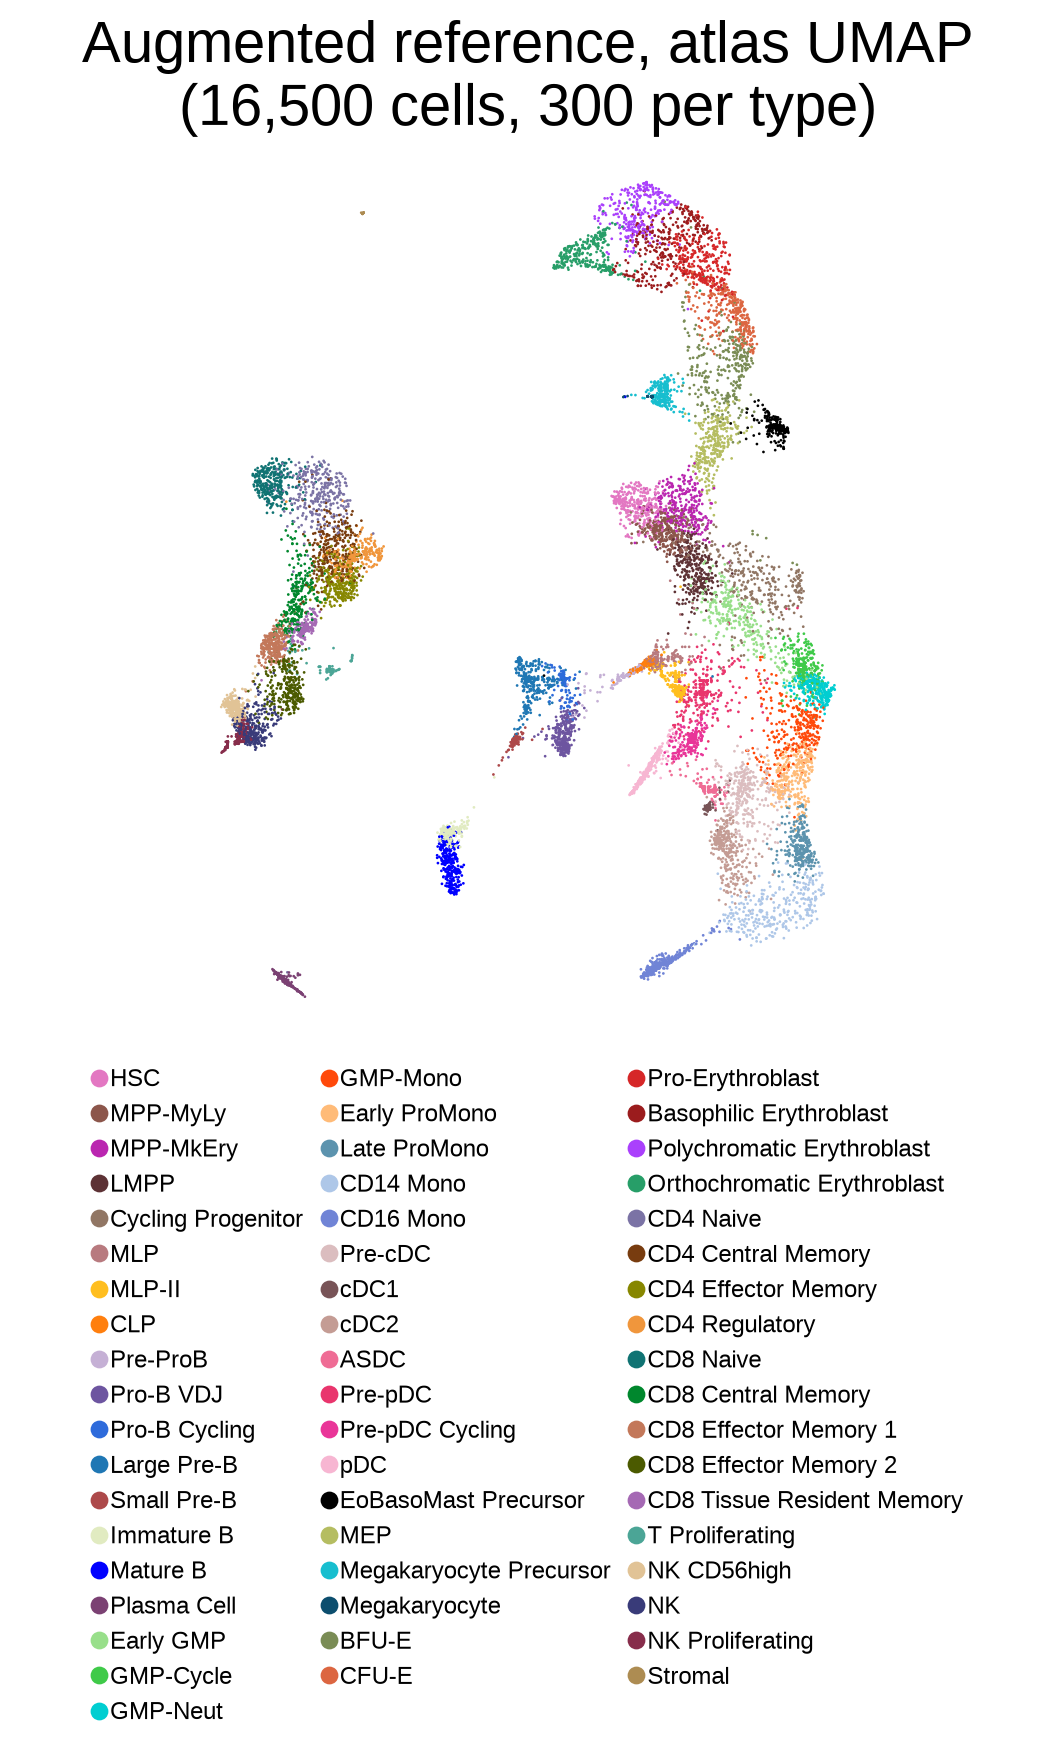

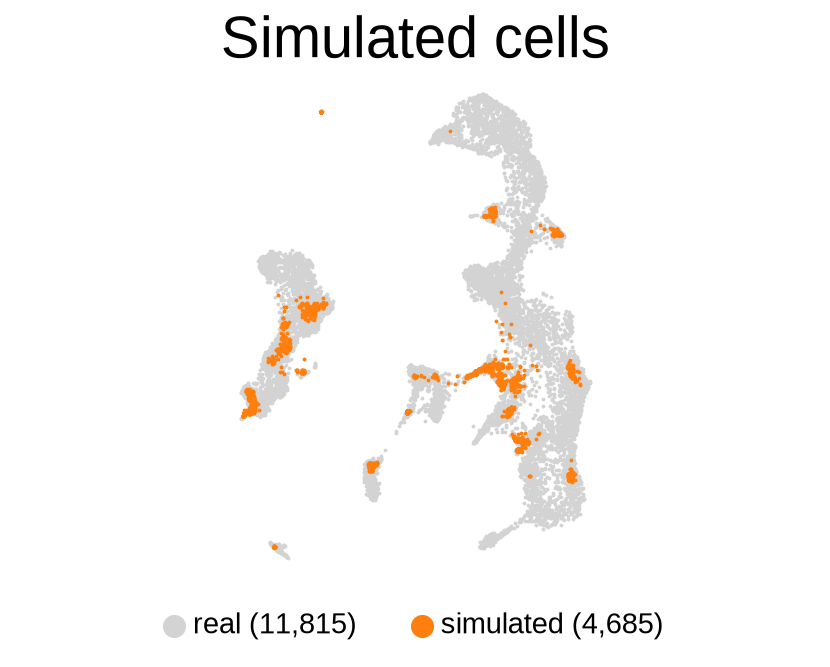

In [4]:
pick = aug.obs.groupby(col, observed=True).sample(300, random_state=0).index
a = aug[pick].copy()
sim = a.obs["simulated"].to_numpy()
sc.pp.normalize_total(a, target_sum=1e4)
sc.pp.log1p(a)
r = a[~sim].copy()  # PCA of the real cells only
sc.pp.highly_variable_genes(r, n_top_genes=3000)
sc.pp.pca(r, n_comps=40, mask_var="highly_variable")
hv = r.var["highly_variable"].to_numpy()
x = a[sim].X[:, hv].toarray() - np.asarray(r.X[:, hv].mean(0)).ravel()
near = NearestNeighbors(n_neighbors=15).fit(r.obsm["X_pca"]).kneighbors(
    x @ r.varm["PCs"][hv], return_distance=False)
xy = atlas_umap.loc[r.obs_names].to_numpy()
a.obsm["X_umap"] = np.zeros((a.n_obs, 2))
a.obsm["X_umap"][~sim] = xy
a.obsm["X_umap"][sim] = np.median(xy[near], axis=1)
# Is the commonest type among a simulated cell's 15 nearest real cells its own type?
own = pd.DataFrame(r.obs[col].astype(str).to_numpy()[near]).mode(axis=1)[0].to_numpy() == a.obs[col].astype(str).to_numpy()[sim]
by_type = pd.Series(own).groupby(a.obs[col].astype(str).to_numpy()[sim]).mean()
print(f"simulated cells whose nearest real cells are mostly their own type: {own.mean():.3f}")
print(by_type.sort_values().head(8).round(3).to_string())
rp.umap_figure(a.obsm["X_umap"], a.obs[col],
               f"Augmented reference, atlas UMAP\n({a.n_obs:,} cells, 300 per type)")
plt.show()
fig, ax = plt.subplots(figsize=(rp.UMAP_W, rp.UMAP_H - 1.4))
for is_sim, c, name in ((False, "lightgrey", "real"), (True, "tab:orange", "simulated")):
    m = sim == is_sim
    ax.scatter(*a.obsm["X_umap"][m].T, s=rp.REF_SIZE * 2, c=c, linewidths=0, rasterized=True,
               label=f"{name} ({m.sum():,})")
ax.set_title("Simulated cells", fontsize=rp.FS_TITLE)
ax.set_aspect("equal", adjustable="datalim")
ax.axis("off")
ax.legend(markerscale=6, frameon=False, fontsize=rp.FS_LEGEND + 2, loc="upper center",
          bbox_to_anchor=(0.5, -0.01), ncol=2)
plt.show()

Most simulated cells sit with the real cells of their type: for 78 % of them, the commonest
type among the 15 nearest real cells is their own type. They still form tight groups, because
they share the pooled profile of their type and vary less than real cells. The rarest type is
the exception: with 44 real cells to pool from, no simulated megakaryocyte has mostly real
megakaryocytes as neighbours. The table above lists the types with the lowest share.

Do not judge this from a new UMAP of the raw counts. In this atlas, such a UMAP puts 96 % of a
real cell's same-type neighbours in its own study (39 % expected if studies mixed). That split
comes from the six studies, not from augmentation: it is the same without simulated cells.

## Does augmentation help the rare types?

Train one model on the real cells only and one on the augmented cells. Both use the genes
that vary in the reference and in the query. Then score both on the held-out real cells.
Recall = share of a type's held-out cells that get the right label. `seed` with
`workers=1` makes training reproducible.

Expect overall accuracy to stay about the same. Mean recall should rise, because the
types with few real cells gain the most. Types that already had many cells change little.

not augmented: accuracy 0.734, mean recall 0.725


augmented: accuracy 0.729, mean recall 0.737
                             not augmented  augmented
CellType                                             
ASDC                                 0.718      0.873
CD4 Regulatory                       0.697      0.749
CD8 Central Memory                   0.409      0.481
CD8 Effector Memory 1                0.751      0.750
CD8 Tissue Resident Memory           0.651      0.725
CLP                                  0.508      0.496
EoBasoMast Precursor                 0.850      0.868
GMP-Cycle                            0.530      0.585
GMP-Neut                             0.812      0.781
Immature B                           0.757      0.843
Large Pre-B                          0.884      0.845
Late ProMono                         0.776      0.763
MLP                                  0.363      0.512
MLP-II                               0.475      0.693
Megakaryocyte                        1.000      1.000
Megakaryocyte Precursor              

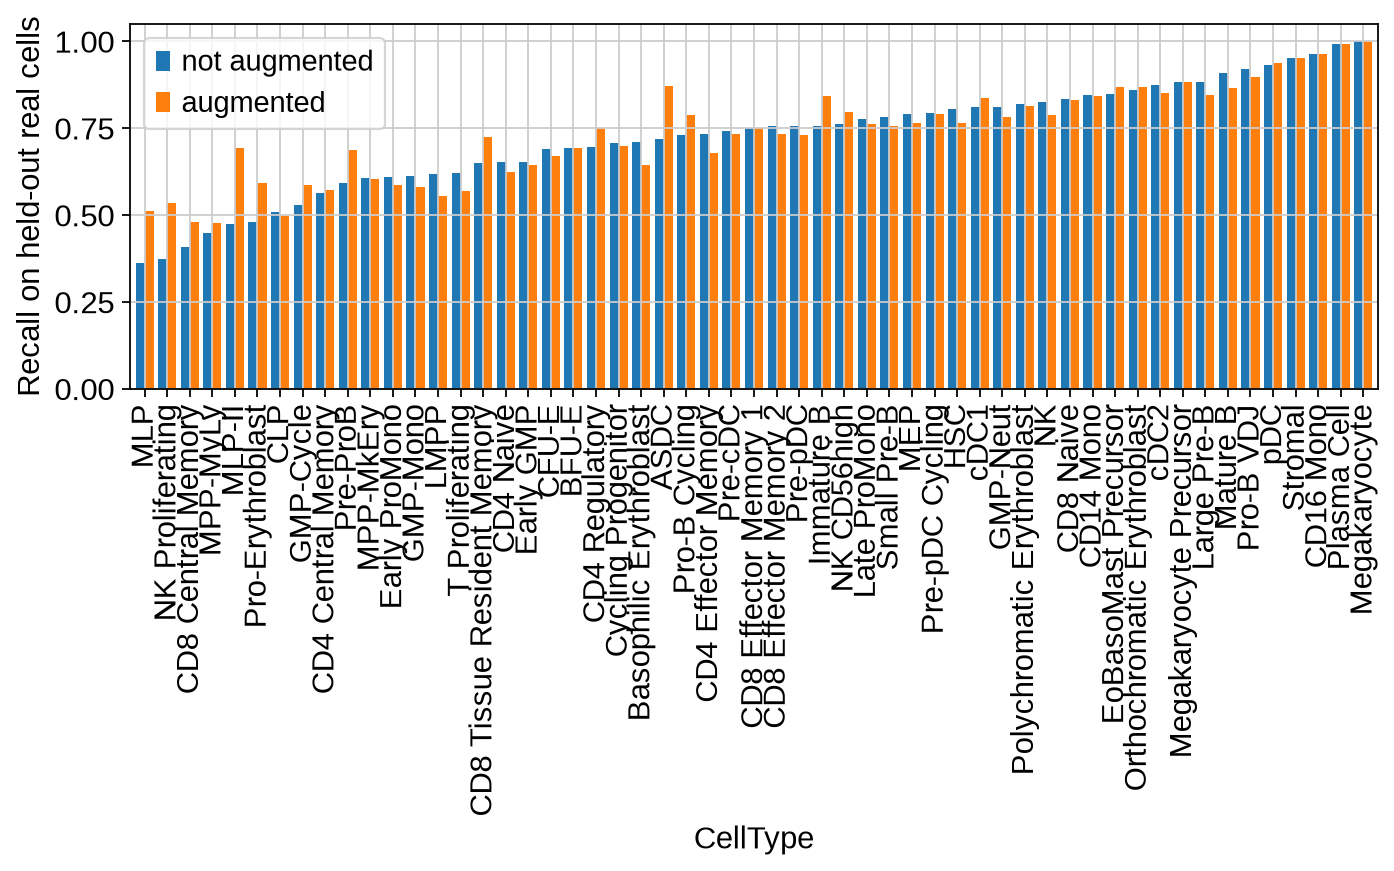

In [5]:
query = td.bm_tcelldep()  # raw counts, the authors' labels and their stored UMAP
vm.calculate_feature_dispersion(query)
vm.select_features(query, top_n=10_000, logmean_ul=-1, logmean_ll=-8)
recall, models = {}, {}
for name, r in (("not augmented", real), ("augmented", aug)):
    vm.calculate_feature_dispersion(r)
    vm.select_features(r, top_n=10_000, logmean_ul=-1, logmean_ll=-8)
    vgr = set(vm.get_selected_features(r))
    vg = [g for g in vm.get_selected_features(query) if g in vgr]
    res = vm.viewmastR(query, r, col, selected_features=vg, query_celldata_col=f"pred_{name}",
                       seed=20261103, workers=1, return_type="list", verbose=False)
    vm.viewmastR_infer(held, res.model_dir, query_celldata_col=f"pred_{name}")
    hit = held.obs[f"pred_{name}"].astype(str) == held.obs[col].astype(str)
    recall[name] = hit.groupby(held.obs[col], observed=True).mean()
    print(f"{name}: accuracy {hit.mean():.3f}, mean recall {recall[name].mean():.3f}")
recall = pd.DataFrame(recall)
print(recall.loc[rare].round(3).to_string())
recall.sort_values("not augmented").plot.bar(figsize=(10, 3), width=0.8)
plt.ylabel("Recall on held-out real cells")
plt.show()

## Label the query with the augmented reference

The query labels came from the augmented model in the loop above. The plots below use the
README figure code (`readme_panels`), so they match the README figure. The heatmap rows are
the predictions; its columns are the authors' labels. Each colour is the fraction of an
author label's cells that get a predicted type. The two vocabularies differ, so read it as a
mapping. Most author types split into two or more finer BoneMarrowMap types. For example,
author `Mono` cells go to CD14 Mono, Late ProMono and Early ProMono; author `NaiveB` cells go
to Immature B and Mature B. The erythroid author types follow the maturation order: `EryPre1`
to Pro-Erythroblast, `EryPre2` to Polychromatic Erythroblast, and `Ery` to Orthochromatic
Erythroblast. One mapping is wrong: the 24 author `Mega` cells get EoBasoMast Precursor, not a
megakaryocyte type. Check small types like this one with marker genes.

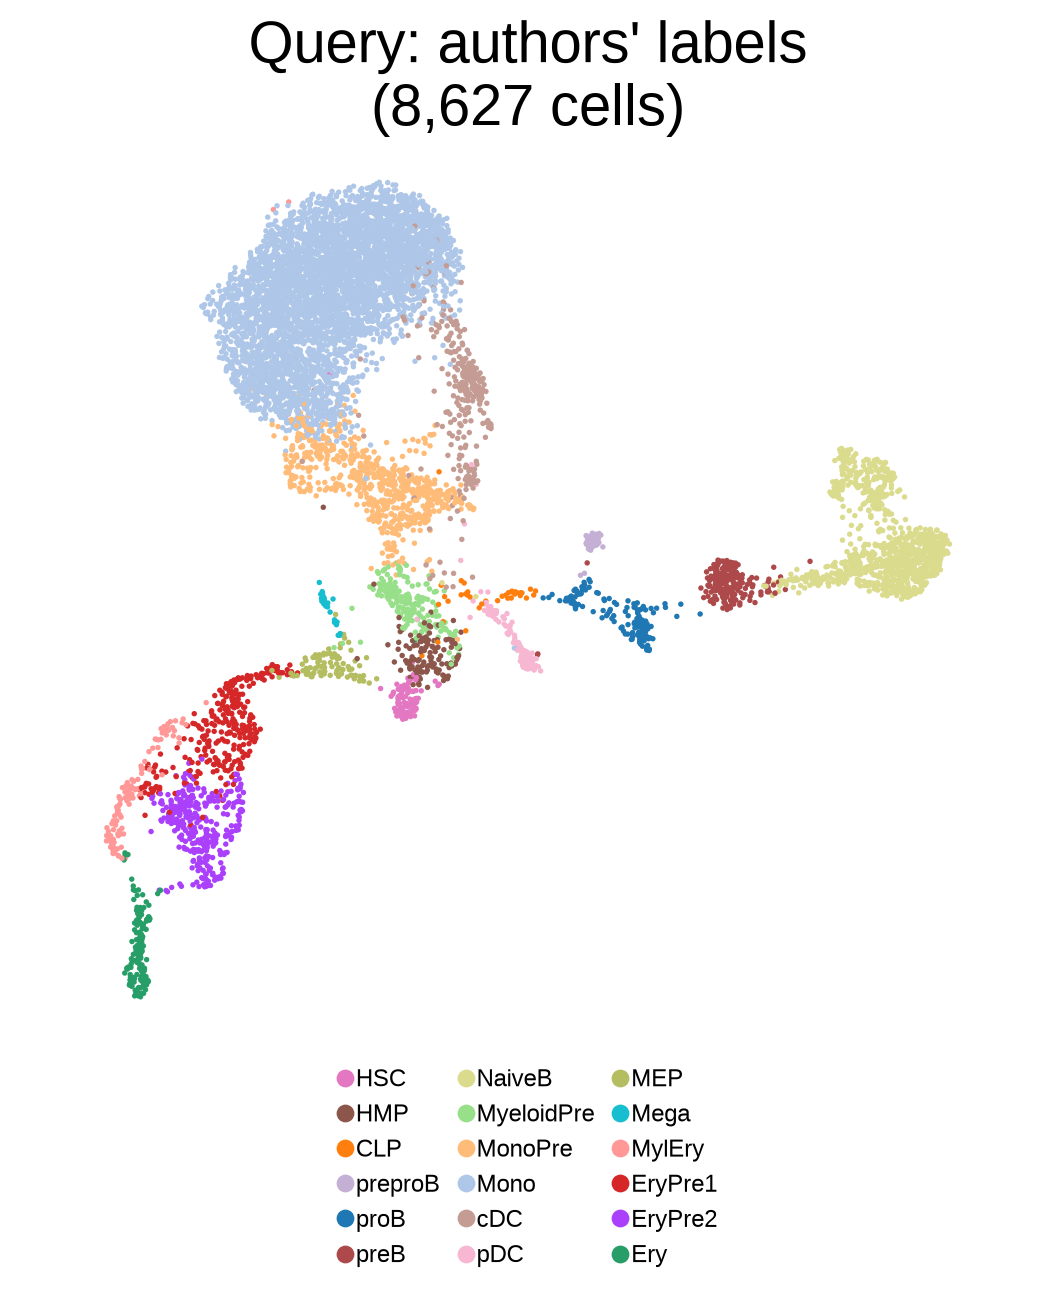

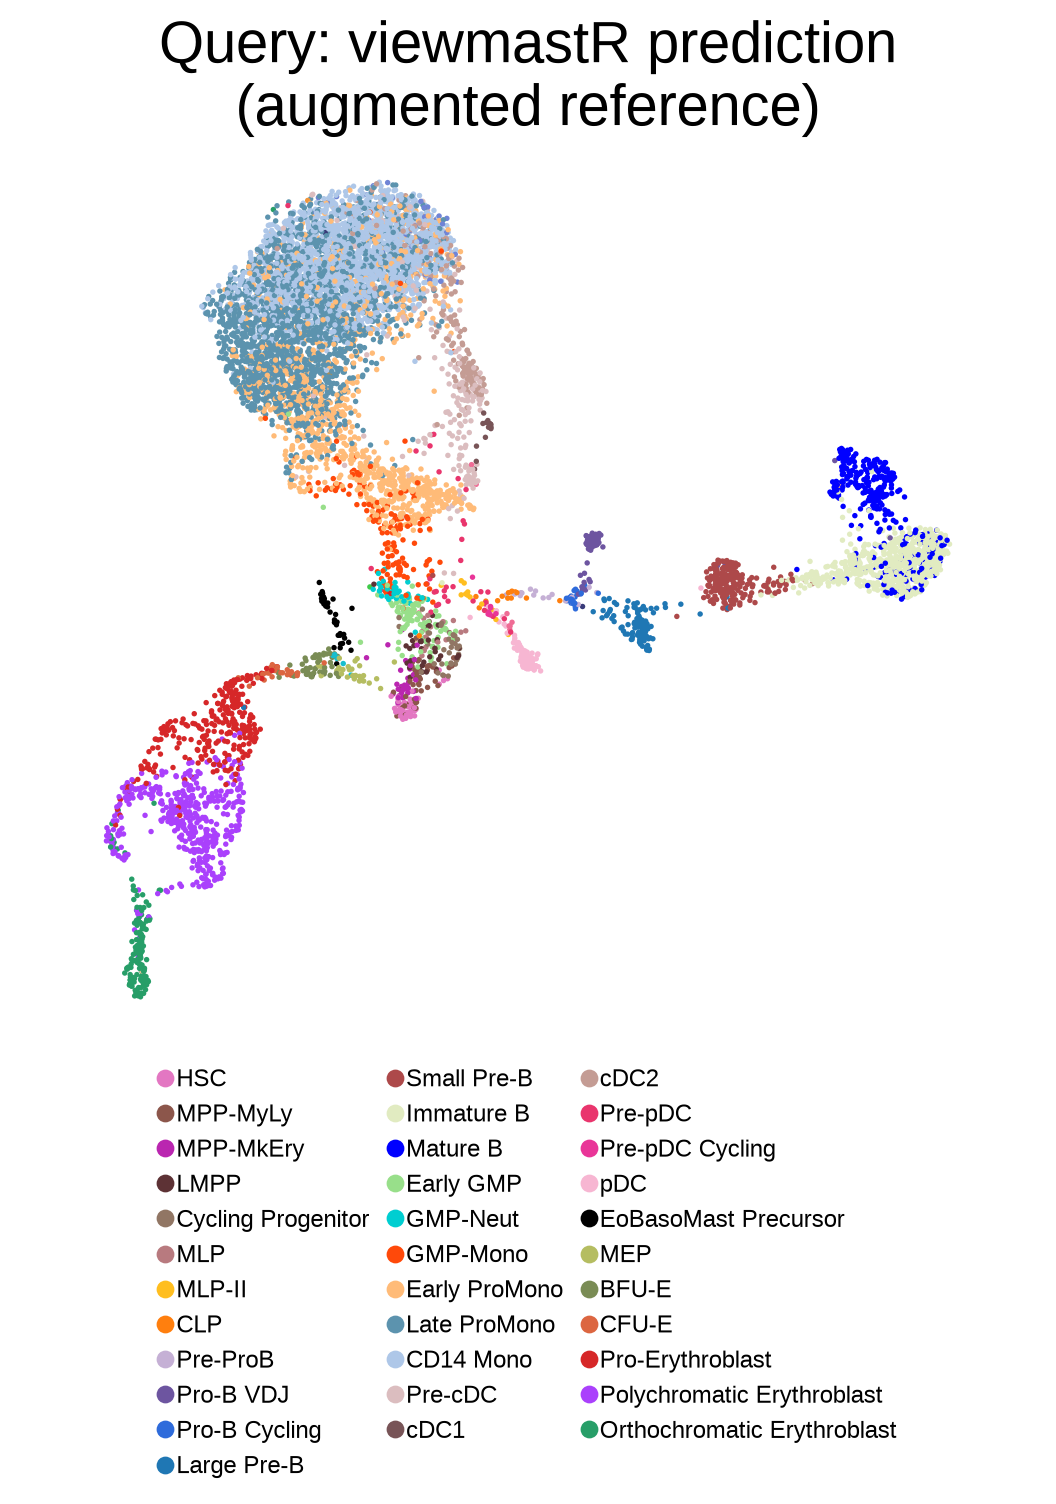

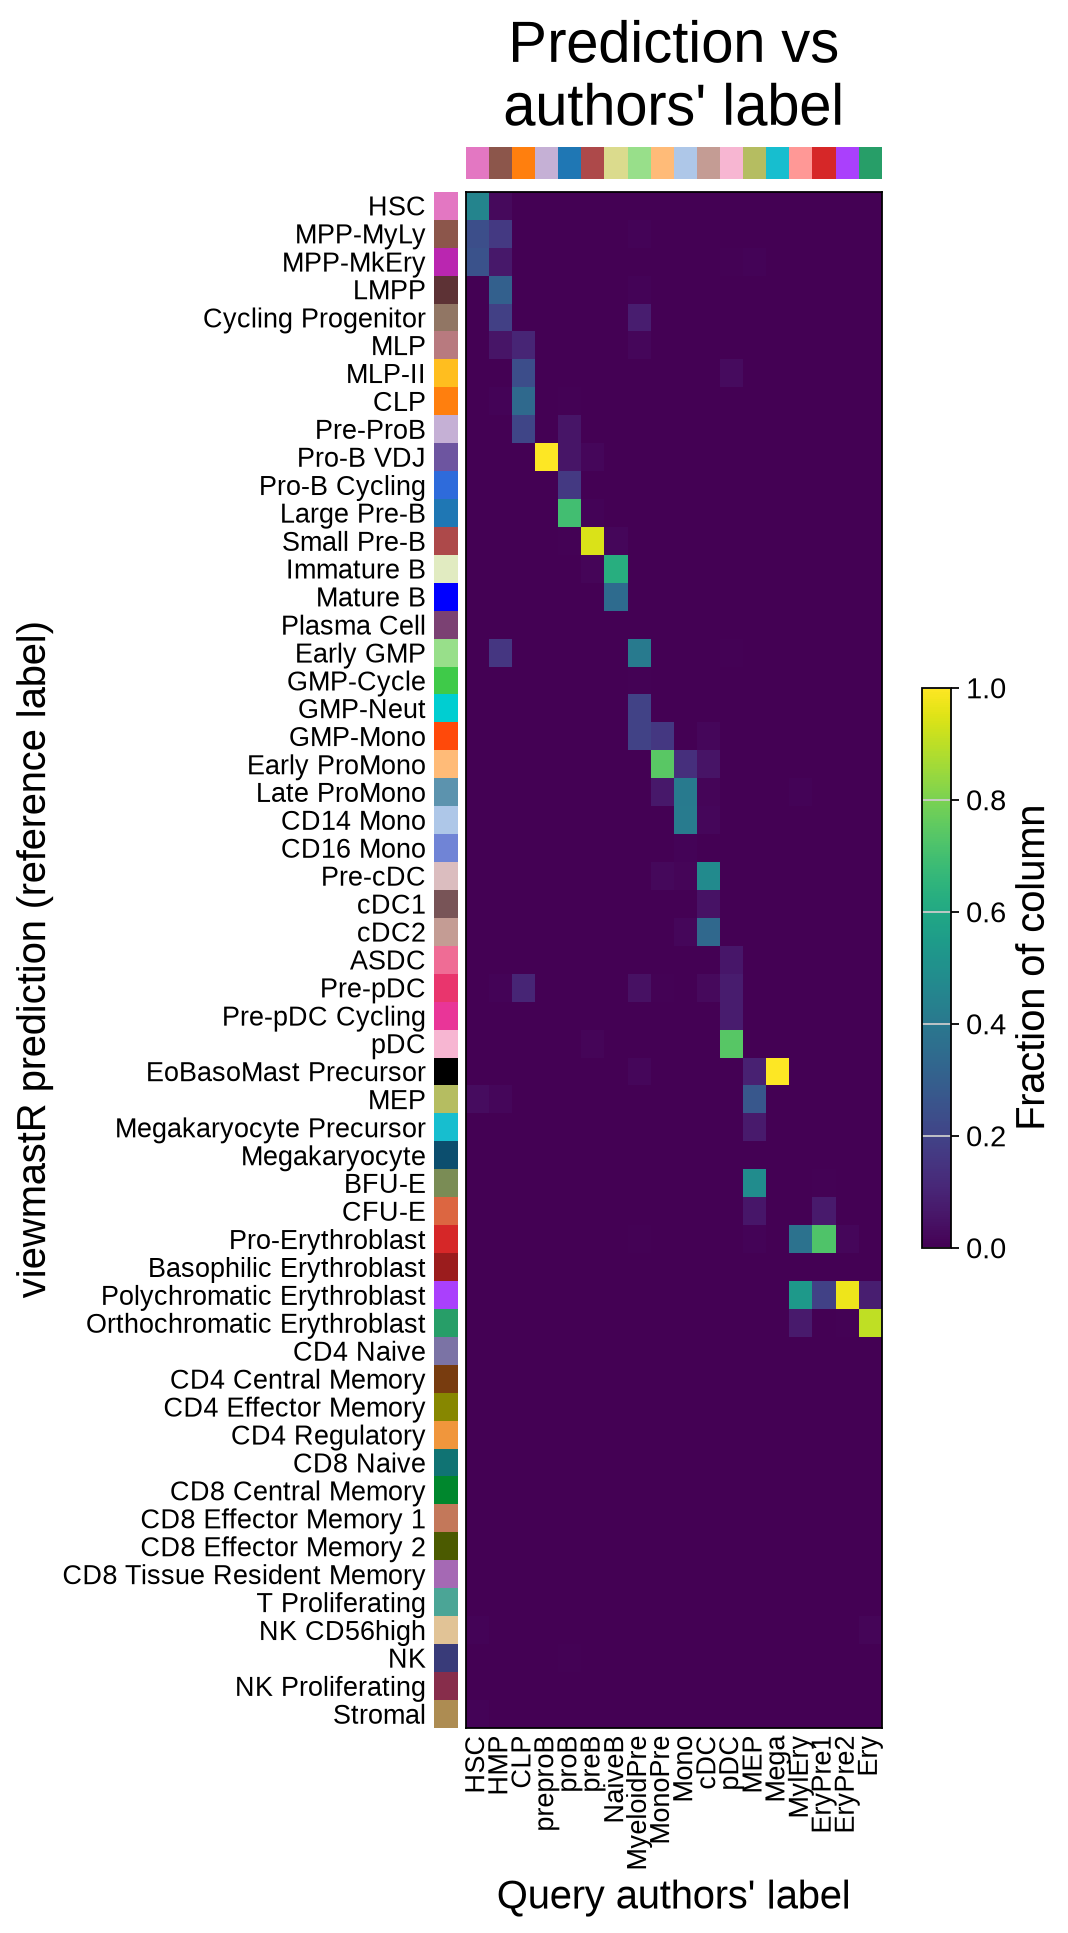

In [6]:
pred, author = query.obs["pred_augmented"], query.obs["celltype"]
query.obs["viewmastR_pred"] = pred
shown, _ = rp.prediction_legend(pred, author)
rp.umap_figure(query.obsm["X_umap"], author,
               f"Query: authors' labels\n({query.n_obs:,} cells)", size=rp.QSIZE)
plt.show()
rp.umap_figure(query.obsm["X_umap"], pred,
               "Query: viewmastR prediction\n(augmented reference)", legend=shown, size=rp.QSIZE)
plt.show()
counts, frac = rp.label_fraction(pred, author)
fig = plt.figure(figsize=(6.5, 11.5))
rp.heatmap_panel(fig, frac, 3.0, 5.6, 1.5, 11.1, cbar=(5.85, 4.5, 0.18, 3.5),
                 title="Prediction vs\nauthors' label")
plt.show()

## Versions

In [7]:
from importlib.metadata import version
for pkg in ("viewmastr", "scanpy", "anndata", "numpy", "scipy"):
    print(f"{pkg:10s} {version(pkg)}")

viewmastr  0.1.0
scanpy     1.12.5
anndata    0.13.4
numpy      2.5.4
scipy      1.18.1
